# Do persistence images improve the equity gate?

October 29, 2026. **Result: no improvement established.** The image model had higher later forecast error and lower gross trading performance than the existing three-summary model. It looked slightly better on earlier point forecasts, which did not carry into the later period. All declared simultaneous incremental intervals span zero.

[Intuitive findings and exact design](experiments/equity_persistence_images/README.md) · [fixed specification](experiments/equity_persistence_images/specification.json) · [source](experiments/equity_persistence_images.py) · [running research log](EQUITY_RESEARCH_LOG.md).

Only the representation changes. The original dollar/SPY/three-PC-neutral daily portfolio and the positive-forecast on/off rule remain fixed. Everything is **gross/pre-fee**. The historical dates were already examined, so this is exploratory research, not a new untouched test.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
cwd = Path.cwd()
candidates = [cwd, cwd/"TDA_Research", cwd/"Senior-Fall"/"TDA_Research", *cwd.parents]
project = next(p for p in candidates if (p/"START_HERE.md").is_file() and (p/"equity").is_dir())
out = project/"equity"/"experiments"/"equity_persistence_images"
result = json.loads((out/"summary.json").read_text())
audit = json.loads((out/"independent_audit.json").read_text())
grid = json.loads((out/"frozen_grid.json").read_text())
features = pd.read_csv(out/"state_features_and_targets.csv")
predictions = pd.read_csv(out/"walk_forward_predictions.csv")
forecast = pd.read_csv(out/"forecast_metrics.csv")
performance = pd.read_csv(out/"gate_performance.csv")
comparisons = pd.read_csv(out/"paired_incremental_comparisons.csv")
pnl = pd.read_csv(out/"daily_gate_returns.csv", parse_dates=["date"])
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Feature anchors:", result["feature_anchors"], "| forecasts:", result["predictions"])
print("First forecast:", result["first_prediction"], "| last:", result["last_prediction"])
print("Complete forecast scores:", result["forecast_scores_by_period"])
print("Daily calendar:", result["calendar_days_by_period"])

Feature anchors: 490 | forecasts: 379
First forecast: 2019-04-18 | last: 2026-10-26
Complete forecast scores: {'boundary': 4, 'development': 233, 'later': 138}
Daily calendar: {'development': 1183, 'later': 708}


## 1. What becomes an image?

We reuse the saved stock diagrams. A point in the original cloud is a stock described by three weighted residual-PCA exposures, estimated from the prior 120 sessions. Distances are divided by their median. The fixed reference set contains 182 stocks; the traded portfolio can admit additional names as their histories arrive.

H1 describes loops in this stock-exposure geometry. A diagram point records the connection distance at which a loop appears and the distance at which it disappears. We use **birth and lifetime (death minus birth)** as axes. These are distance scales, not days or economic cycles.

Place a smooth Gaussian bump at each point, weight it by lifetime, then integrate the bumps into sixteen pixels. Each pixel is one input to the same small regression. Longer lifetime gets more weight by construction; it is not proof of stronger return predictability. This is a vector representation, not a screenshot passed to a neural network. See [Adams et al. (2017)](https://www.jmlr.org/papers/volume18/16-337/16-337.pdf).

All H0 components start at zero, so their useful coordinate is their merge distance. We use four frequency bins instead of allocating a second image dimension to a constant. One infinite interval is excluded. **Four H0 bins plus sixteen H1 pixels give twenty added inputs.**

The grid uses only diagrams from the first forecast's 104 completed training labels. Its bounds are 1.25 times the initial maxima, with Gaussian width half a pixel. They stay fixed; feature scaling and regression coefficients update from completed training history only. No resolution or bandwidth search was performed.

{'first_prediction_anchor': 111, 'first_prediction_date': '2019-04-18', 'calibration_labels': 104, 'latest_calibration_target_end': '2019-04-18', 'H0_upper': 0.6788800656795502, 'birth_upper': 0.872187465429306, 'lifetime_upper': 0.3467222303152085, 'birth_sigma': 0.10902343317866325, 'lifetime_sigma': 0.04334027878940106}


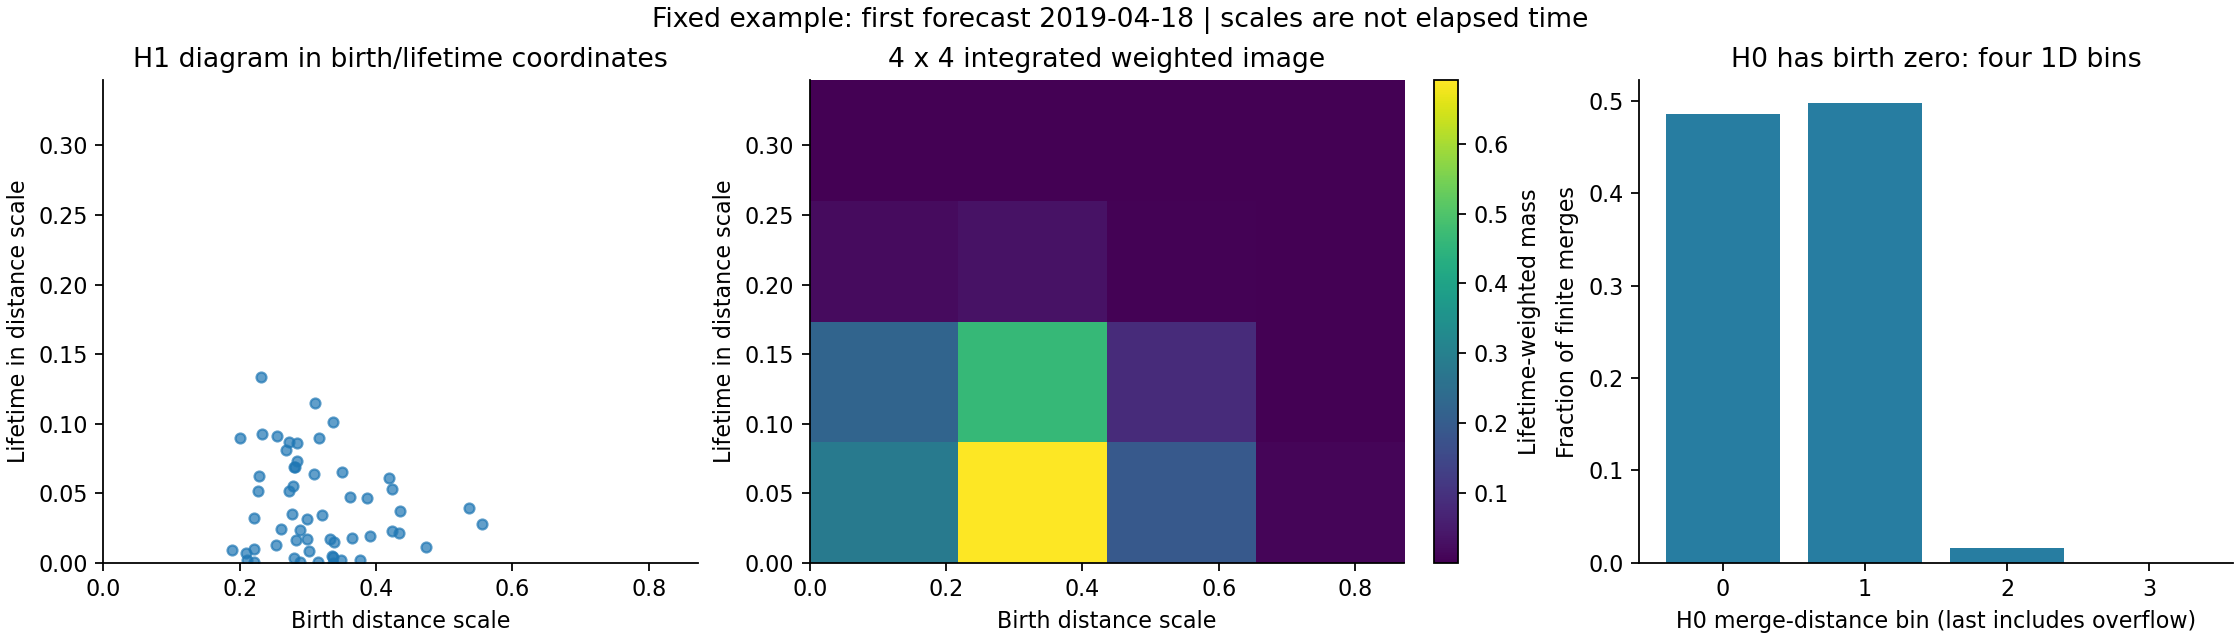

In [2]:
print({k: v for k, v in grid.items() if k != "calibration_anchors"})
display(Image(filename=str(out/"01_diagram_to_image.png")))

## 2. Did the richer representation predict returns better?

The target is the average gross daily return over the next twenty **daily strategy trades**, not holding today's weights for twenty days. Forecasts update every five sessions. All models share the previous ordinary state predictors, including volatility, correlations, PCA concentration, temporal summaries, recent strategy performance, stock count, and cloud scales.

`SimplePlusStockPD` adds the old three summaries. `Ordinary20` adds twenty conventional distance/correlation quantiles. `PersistenceImage20` adds the four H0 bins and sixteen image pixels. The latter two have equal added feature count, although their effective complexity can differ. `HistoryMean` simply predicts the average of completed historical target windows.

**Lower mean squared error is better.** The image's later error is 38.103 versus 32.812 for the three-summary model. Earlier, the image's point error was slightly lower than the simple and three-summary models. Its historical advantage did not persist across these periods. No causal reason for that change is identified.

We report paired approximate 95% simultaneous bands across the three image-minus-comparator contrasts within each period and metric. Every such interval includes zero. The forecast bootstrap resamples twelve consecutive five-session anchors at a time to acknowledge dependence. It conditions on the saved forecasts rather than refitting the entire model each time.

,period,model,forecasts,MSE_bps_squared,MAE_bps
0,development,HistoryMean,233,79.2784,5.9011
1,development,Simple,233,71.1527,5.7541
2,development,SimplePlusStockPD,233,71.4226,5.7872
3,development,Ordinary20,233,80.8005,6.2399
4,development,PersistenceImage20,233,70.1283,5.7073
5,later,HistoryMean,138,32.2774,4.6935
6,later,Simple,138,33.3471,4.7297
7,later,SimplePlusStockPD,138,32.8116,4.7006
8,later,Ordinary20,138,32.6802,4.7646
9,later,PersistenceImage20,138,38.1033,4.9956


,period,comparator,difference,sim95_low,sim95_high
0,development,Simple,-1.0244,-4.5071,2.4584
1,development,SimplePlusStockPD,-1.2943,-4.6688,2.0803
2,development,Ordinary20,-10.6722,-23.0570,1.7127
6,later,Simple,4.7562,-1.1956,10.7080
7,later,SimplePlusStockPD,5.2916,-0.5785,11.1617
8,later,Ordinary20,5.4231,-3.5436,14.3897


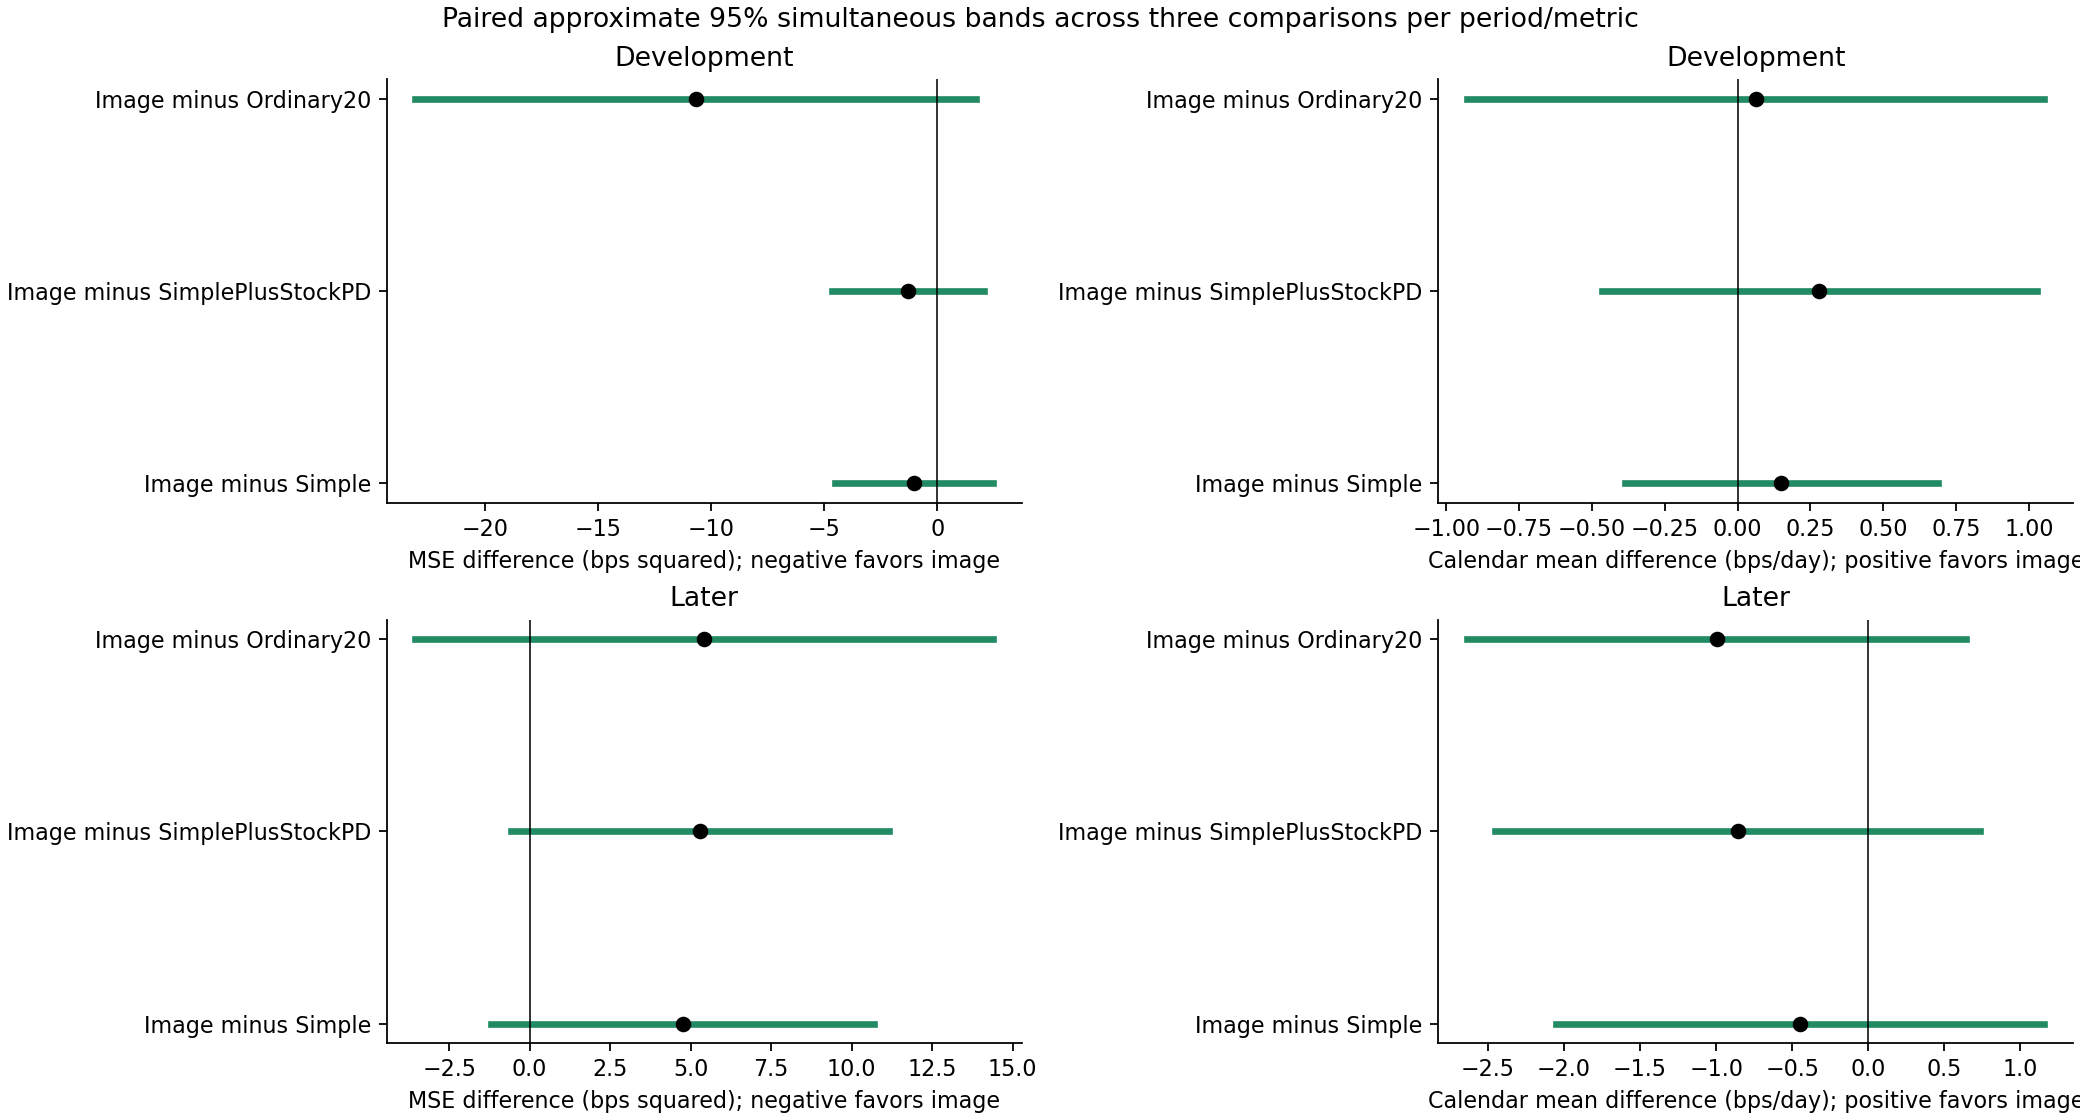

In [3]:
display(forecast[["period", "model", "forecasts", "MSE_bps_squared", "MAE_bps"]].round(4))
display(comparisons.loc[comparisons.metric.eq("forecast_MSE_bps_squared"),
    ["period", "comparator", "difference", "sim95_low", "sim95_high"]].round(4))
display(Image(filename=str(out/"03_incremental_comparisons.png")))

## 3. What happened to gross profit?

A forecast above zero runs the existing strategy for the next five sessions; otherwise it holds no stock positions. During active sessions, weights still refresh daily, enter at the next daily-bar open, and close that day. All flat days remain zero in the calendar series.

Later image-gate CAGR is **1.19%**, Sharpe **0.43**, versus **3.39%** and **1.06** for the three-summary gate. The ordinary twenty-coordinate control has higher later point performance than either, but it is not a validated winner. All daily mean intervals include zero. No costs of any kind are deducted.

The image-minus-three-summary later mean difference is **−0.857 bps/calendar day**, approximate simultaneous interval **[−2.451,+0.737]**. The point result is unfavorable, but the uncertainty does not establish a definitive ranking. Calendar intervals use sixty-session blocks. Curves start from zero separately in each period.

,period,model,mean_daily_bps,mean_low,mean_high,CAGR_percent,sharpe_vs_zero,active_percent
0,development,AlwaysOn,-0.197,-2.859,2.625,-0.590,-0.114,100.000
1,development,HistoryMean,-0.175,-1.444,0.935,-0.465,-0.194,38.462
2,development,Simple,0.407,-1.655,2.916,0.977,0.315,40.575
3,development,SimplePlusStockPD,0.276,-1.822,2.762,0.644,0.213,40.152
4,development,Ordinary20,0.495,-1.622,2.885,1.192,0.353,51.141
5,development,PersistenceImage20,0.557,-1.691,3.078,1.365,0.454,38.884
6,later,AlwaysOn,1.343,-0.634,3.360,3.367,0.890,100.000
7,later,HistoryMean,0.486,-1.322,2.320,1.169,0.348,83.475
8,later,Simple,0.933,-0.681,2.558,2.327,0.739,67.232
9,later,SimplePlusStockPD,1.344,-0.264,2.891,3.391,1.056,69.350


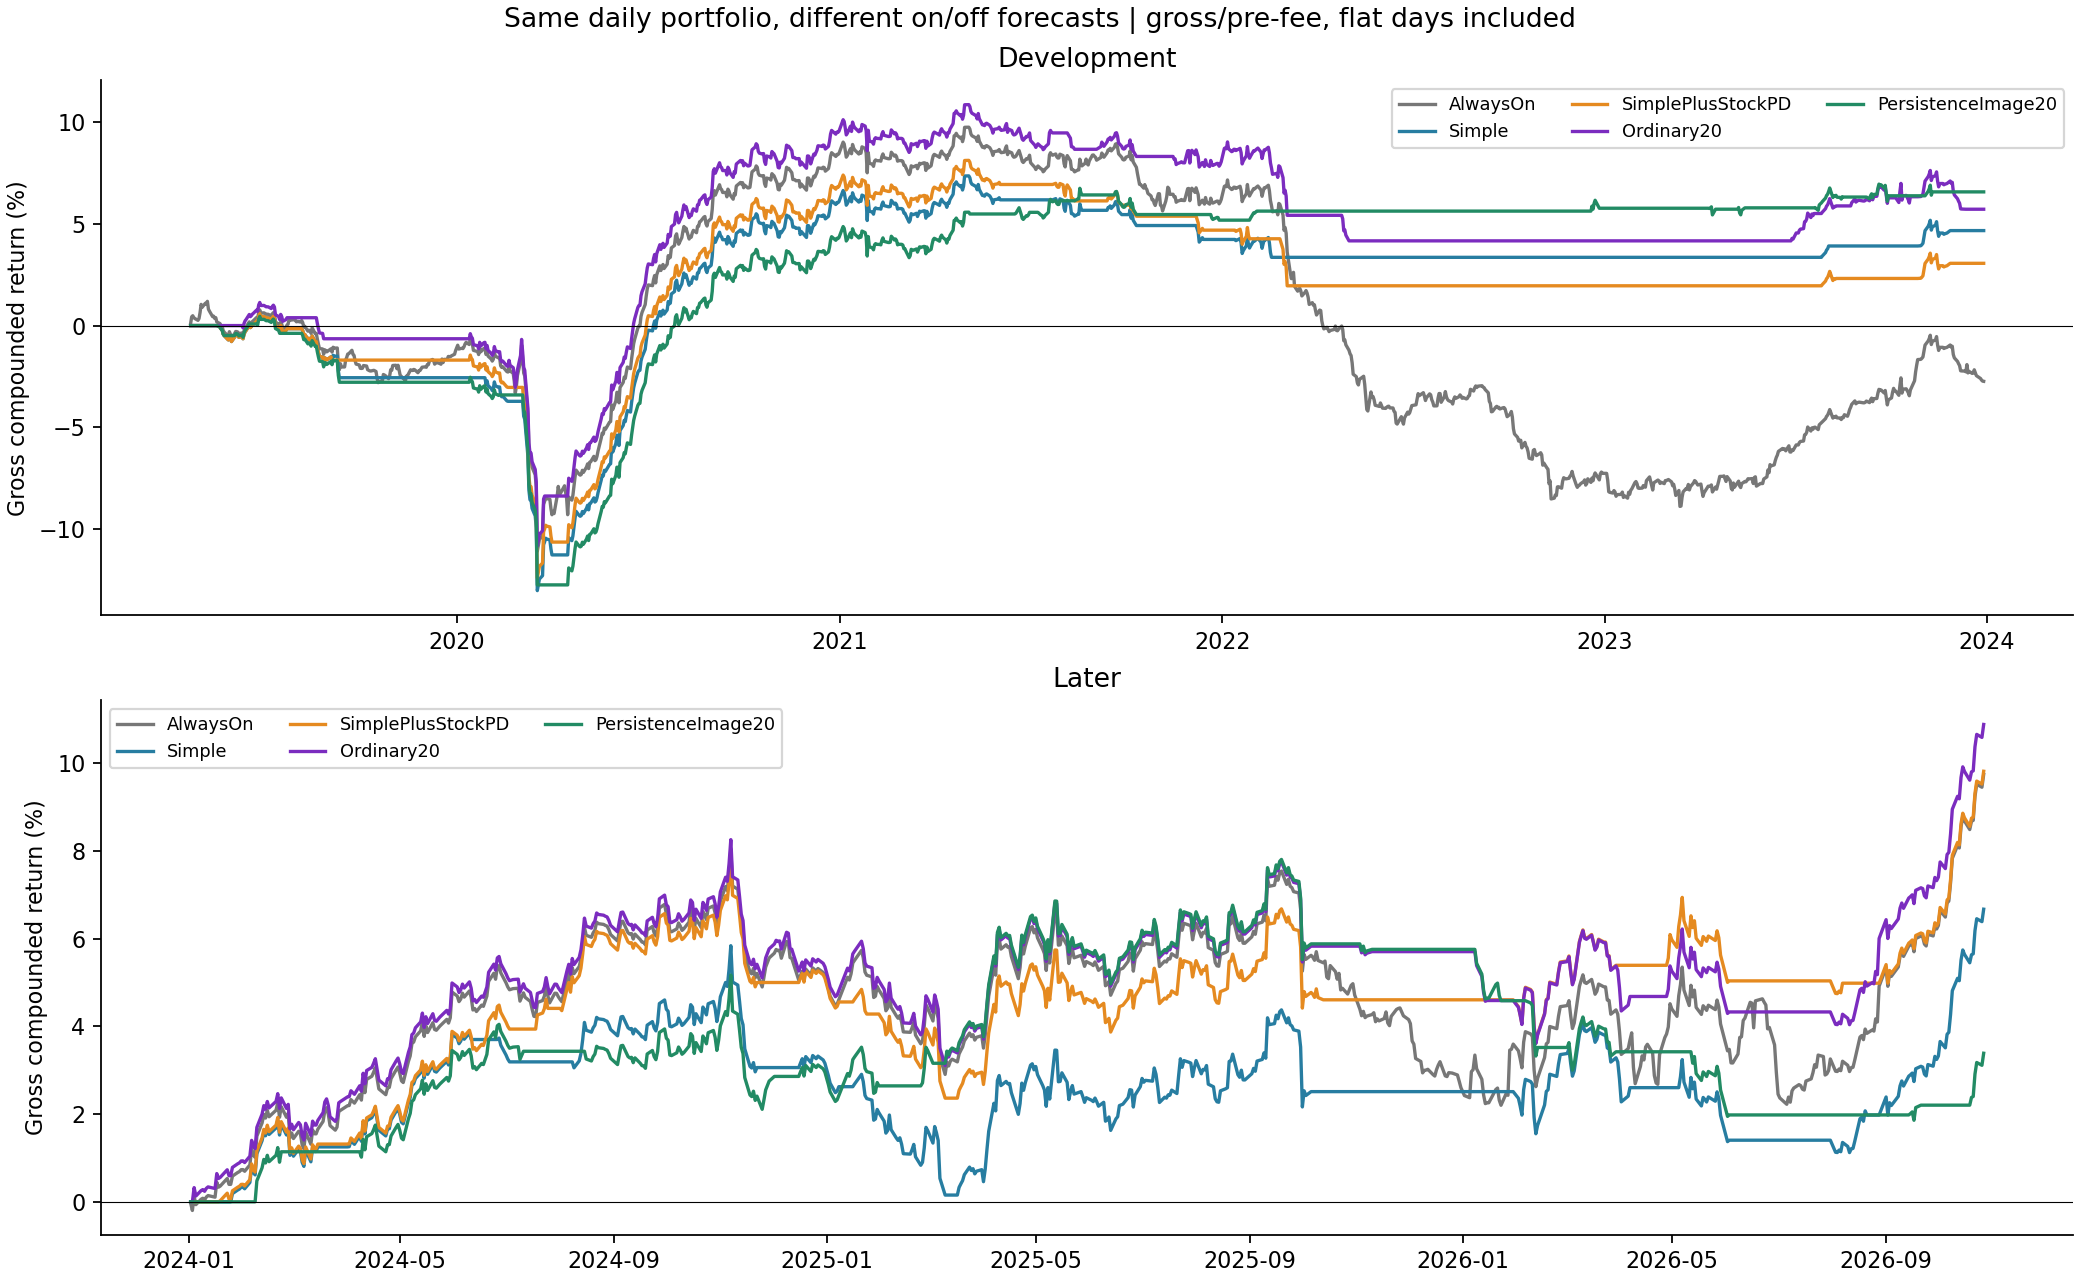

In [4]:
table = performance.copy()
table["CAGR_percent"] = table.gross_CAGR*100
table["active_percent"] = table.active_fraction*100
display(table[["period", "model", "mean_daily_bps", "mean_low", "mean_high", "CAGR_percent", "sharpe_vs_zero", "active_percent"]].round(3))
display(Image(filename=str(out/"02_gross_gate_profit.png")))

## 4. Did it skip useful trades? Did the grid fail?

The table below is a **descriptive decomposition**, not a new fitted rule: what did the underlying strategy earn on days a gate allowed it to trade versus days it skipped? The gate's calendar mean equals active fraction times the underlying mean on active days. Positive skipped-day returns are gains the gate omitted; negative skipped-day returns are losses it avoided. These realized subgroup means cannot be known at decision time.

For the later image gate, the underlying portfolio averaged **0.870 bps on active days and 1.942 bps on skipped days**. It skipped the more profitable group in this sample. Earlier it had the desired ordering: +1.433 active versus −1.235 skipped. This does not establish why the relationship changed or a statistically reliable ranking.

Separately, only 3 of 30,270 H1 points lie outside the fixed rectangle across all feature anchors. Median retained weighted Gaussian mass is 88.6%, including ordinary tails outside the nonnegative grid. H0 overflow is retained in the last bin. This argues against widespread range overflow; it does not prove that the chosen smoothing or grid is best.

,period,model,active_fraction,underlying_active_day_mean_bps,underlying_skipped_day_mean_bps
0,development,Simple,0.4057,1.0029,-1.0168
1,development,SimplePlusStockPD,0.4015,0.6881,-0.7914
2,development,Ordinary20,0.5114,0.9682,-1.4173
3,development,PersistenceImage20,0.3888,1.4331,-1.2347
4,later,Simple,0.6723,1.3874,1.2509
5,later,SimplePlusStockPD,0.6935,1.9376,-0.0033
6,later,Ordinary20,0.8206,1.8073,-0.7826
7,later,PersistenceImage20,0.5593,0.8702,1.9424


H1_outside_points_total               3.000000
H1_total_points                   30270.000000
minimum_mass_retained_fraction        0.831441
median_mass_retained_fraction         0.886154
H0_upper_overflows_total              2.000000
Name: Range checks, dtype: float64

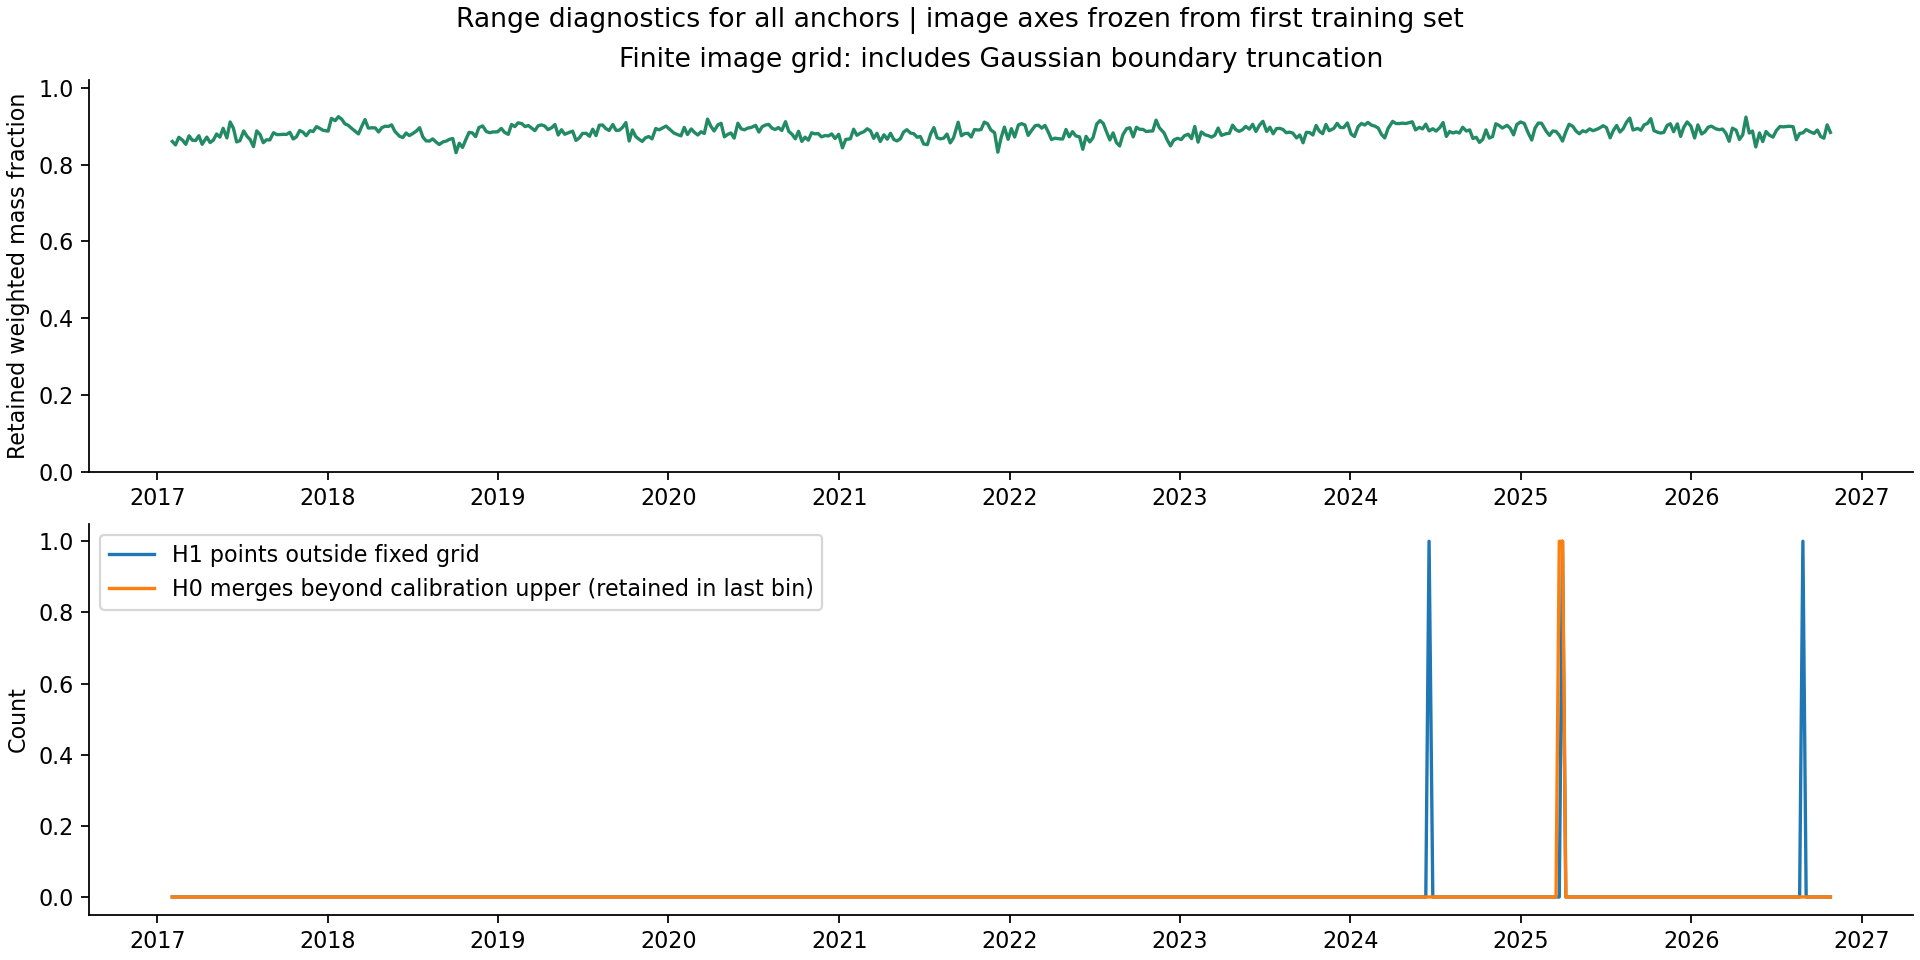

In [5]:
selection = []
for period, days in pnl.groupby("period", sort=False):
    for model in ["Simple", "SimplePlusStockPD", "Ordinary20", "PersistenceImage20"]:
        active = days[model+"_active"].astype(bool)
        active_mean = days.loc[active, "AlwaysOn"].mean()*1e4
        skipped_mean = days.loc[~active, "AlwaysOn"].mean()*1e4
        assert np.isclose(active.mean()*active_mean, days[model].mean()*1e4)
        assert np.isclose(active.mean()*active_mean+(~active).mean()*skipped_mean, days.AlwaysOn.mean()*1e4)
        selection.append({"period": period, "model": model, "active_fraction": active.mean(),
            "underlying_active_day_mean_bps": active_mean, "underlying_skipped_day_mean_bps": skipped_mean})
selection = pd.DataFrame(selection)
selection.to_csv(out/"gate_selection_diagnostics.csv", index=False)
display(selection.round(4))
display(pd.Series(result["range_diagnostics"], name="Range checks"))
display(Image(filename=str(out/"04_image_coverage.png")))

## 5. What we learned and what remains uncertain

The image preserves a real distinction omitted by lifetime summaries: hypothetical diagrams with equal lifetimes but shifted births produce different pixels. Empty and zero-lifetime H1 contribute zero, and reordering diagram points changes nothing. But preserving more diagram information did not yield demonstrated forecasting value in this test.

The checks below reconstruct every image and forecast independently, preserve completed-label chronology, and reconcile the old baseline, daily P&L, metrics, and uncertainty bands. These checks address implementation errors; they do not prove a strategy edge or establish why the image model underperformed.

Additional estimation noise, a weak relationship between shape and returns, and an unsuitable representation are possible explanations. This run cannot distinguish them. The survivor universe, already examined history, overlapping windows, single grid choice, and fixed learner remain limitations.

**Decision:** keep this as a negative incremental result. Retain the daily strategy as an unconfirmed benchmark; do not promote the tested gates or tune a larger image merely to repair this curve. New observations or a distinct justified hypothesis would be more informative than selecting the best pixel settings on the same history.

In [6]:
for name, passed in audit["checks"].items():
    print(name, passed)
print("Images checked:", audit["images_checked"], "| forecasts checked:", audit["forecasts_checked"])
print("Maximum independent image error:", audit["max_image_error"])
print("Maximum independent forecast error, bps:", audit["max_prediction_error_bps"])
assert all(audit["checks"].values())

frozen_grid_uses_first_completed_training_set_only True
all_images_and_H0_bins_independently_reconstructed True
Gaussian_integrals_confirmed_by_quadrature True
ordinary_features_covariance_eigen_check True
every_forecast_and_coefficient_matches_sklearn True
exact_completed_label_membership_and_future_label_exclusion True
all_calendar_days_and_flat_returns_reconcile True
baseline_forecasts_match_original True
every_metric_and_paired_uncertainty_band_reproduced True
protected_inputs_unchanged True
Images checked: 490 | forecasts checked: 379
Maximum independent image error: 5.551115123125783e-16
Maximum independent forecast error, bps: 4.849454171562684e-13
